# Titanic

The target is a binary variable, indicating whether a person survived the sinking of the Titanic.
Other variables:
* PassengerId - unique identifier
* Pclass - ticket class; a proxy for socio-economic status (SES) (1 = Upper|2 = Middle|3 = Lower)
* Name - passenger's name
* Sex - sex (male/female)
* Age - age in years
* SibSp - number of siblings / spouses aboard the Titanic
* Parch - number of parents / children aboard the Titanic
* Ticket - ticket number
* Fare - passenger fare
* Cabin - cabin number
* Embarked - port of embarkation (C = Cherbourg|Q = Queenstown|S = Southampton)

## Import libraries

In [68]:
import torch

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, QuantileTransformer

from config import config

## EDA

In [69]:
df = pd.read_csv(config.paths.path_to_dataset)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [70]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [71]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


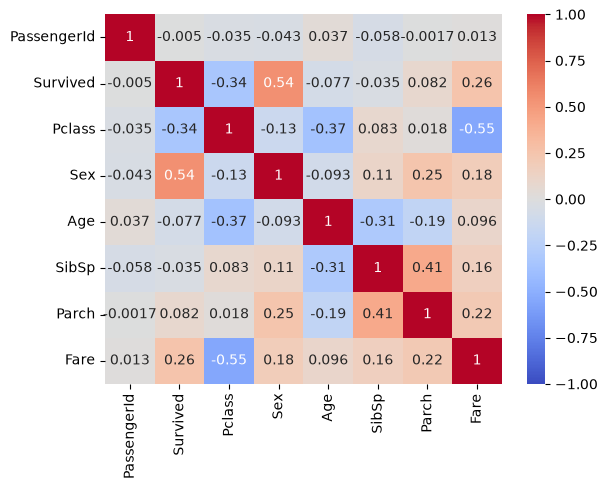

In [72]:
df_copy = df.copy()
df_copy.Sex = np.where(df_copy.Sex == 'male', 0, 1)
corr = df_copy.corr(numeric_only=True)
sns.heatmap(corr, vmin=-1, vmax=1, center=0, annot=True, cmap='coolwarm')
plt.show()

In [73]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [74]:
def get_deck(cabin):
    if type(cabin) == float:
        return 'Unknown'
    parts = cabin.split()
    if len(parts) == 1:
        return cabin[0]
    for part in parts:
        if len(part) > 1:
            return part[0]
    return 'Unknown'

df['Deck'] = df['Cabin'].apply(get_deck)
df['Surname'] = df['Name'].apply(lambda x: x[:x.find(',')])
df['Title'] = df['Name'].apply(lambda x: x[x.find(',')+2:x.find('.')])
df.loc[~df.Title.isin(['Mr', 'Miss', 'Mrs', 'Master']), 'Title'] = 'Rare'
df['FamilySize'] = pd.cut(
    df['SibSp'] + df['Parch'],
    bins=[-1, 0, 2, 5, np.inf],
    labels=['Solo', 'Small', 'Medium', 'Big'],
).astype(str)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Deck,Surname,Title,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Unknown,Braund,Mr,Small
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,C,Cumings,Mrs,Small
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Unknown,Heikkinen,Miss,Solo
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,C,Futrelle,Mrs,Small
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Unknown,Allen,Mr,Solo


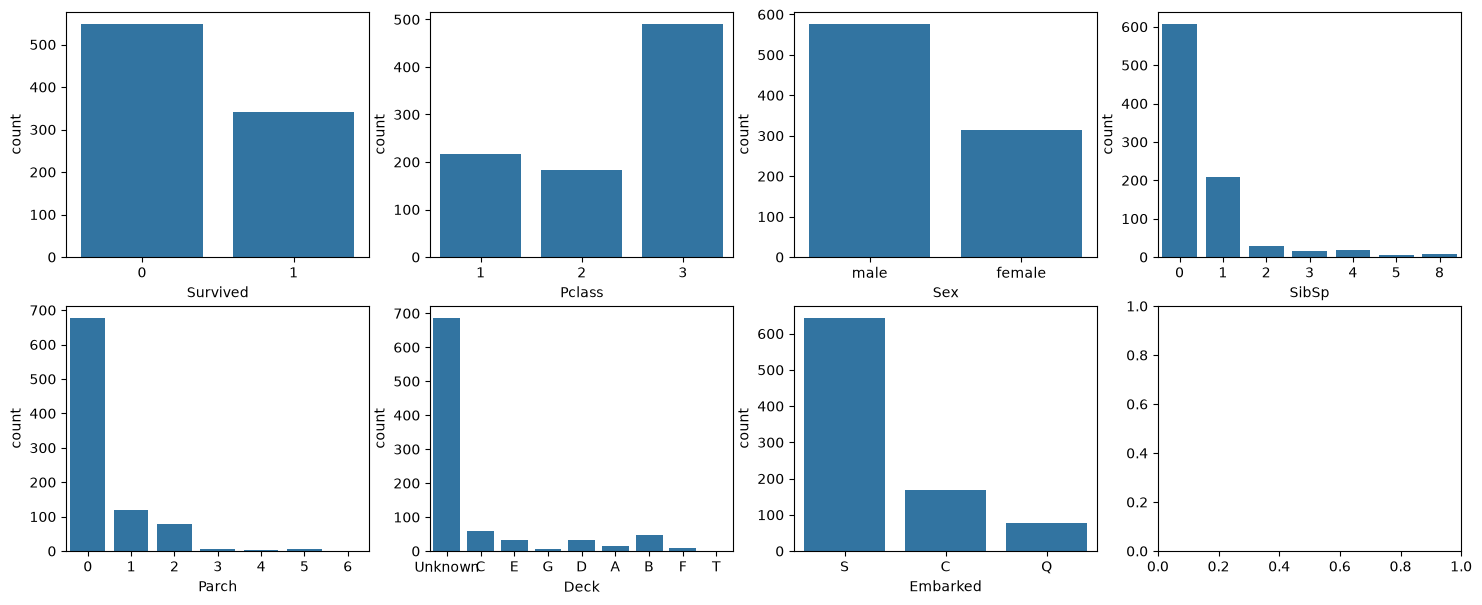

In [75]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
sns.countplot(df, ax=axes[0, 0],  x='Survived')
sns.countplot(df, ax=axes[0, 1],  x='Pclass')
sns.countplot(df, ax=axes[0, 2],  x='Sex')
sns.countplot(df, ax=axes[0, 3],  x='SibSp')
sns.countplot(df, ax=axes[1, 0],  x='Parch')
sns.countplot(df, ax=axes[1, 1],  x='Deck')
sns.countplot(df, ax=axes[1, 2],  x='Embarked')

plt.show()

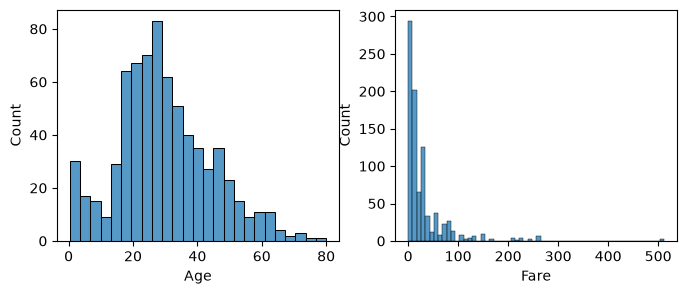

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sns.histplot(df, ax=axes[0], x='Age', bins=25)
sns.histplot(df, ax=axes[1], x='Fare')
plt.show()

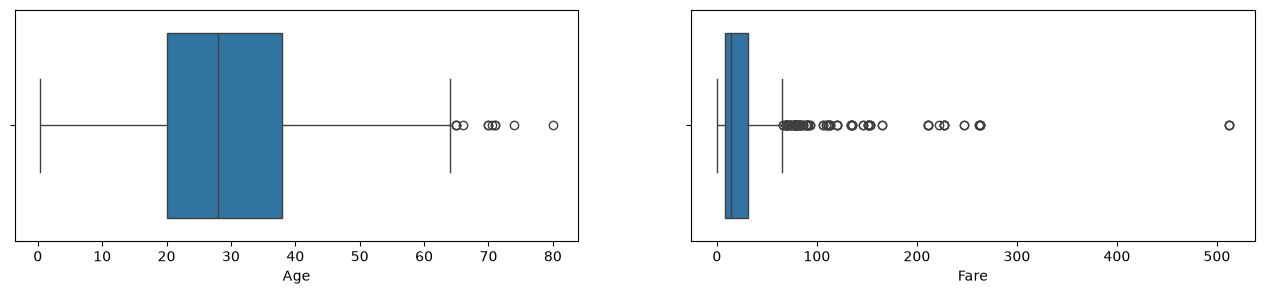

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))
sns.boxplot(df, ax=axes[0], x='Age')
sns.boxplot(df, ax=axes[1], x='Fare')
plt.show()

In [78]:
is_eval_imputer = False
if is_eval_imputer:
    import time

    from sklearn.model_selection import KFold, train_test_split
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from sklearn.experimental import enable_iterative_imputer
    from sklearn.impute import IterativeImputer
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import BayesianRidge
    from sklearn.neighbors import KNeighborsRegressor
    from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

    from custom_transformers import GroupStatImputer, EstimatorImputer


    X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Deck', 'Title', 'IsGroupTicket']]
    y = df.Survived

    data: pd.DataFrame = train_test_split(
        X,
        y, 
        test_size=config.general.test_size, 
        random_state=config.general.seed,
        stratify=y
    )[0]
    data = data[data['Age'].notna()]
    age_true = data.Age

    cat_cols = ['Sex', 'Embarked', 'Deck', 'Title']
    num_cols = ['Fare', 'Parch', 'SibSp']
    splitter = KFold(n_splits=5, shuffle=True, random_state=42)
    group_oof_median = np.full(len(data), np.nan)
    group_oof_mean = np.full(len(data), np.nan)
    estimator_oof = np.full(len(data), np.nan)
    iterative_oof_1 = np.full(len(data), np.nan)
    iterative_oof_2 = np.full(len(data), np.nan)
    iterative_oof_3 = np.full(len(data), np.nan)

    estimator_imputer_times = []
    iterative_imputer_times = []

    def encode(ohe, X):
        encoded = pd.DataFrame(
            ohe.transform(X[cat_cols]),
            columns=ohe.get_feature_names_out(cat_cols),
            index=X.index,
        )
        return pd.concat([X.drop(columns=cat_cols), encoded], axis=1)

    for train_index, val_index in splitter.split(data):
        train = data.iloc[train_index]
        val = data.iloc[val_index]
        val['Age'] = np.nan

        # GroupStatImputer
        group_imputer_median = GroupStatImputer(target_col='Age', group_cols=['Title'], method='median')
        group_imputer_median.fit(train)
        group_oof_median[val_index] = group_imputer_median.transform(val)['Age'].to_numpy()

        group_imputer_mean = GroupStatImputer(target_col='Age', group_cols=['Title'], method='mean')
        group_imputer_mean.fit(train)
        group_oof_mean[val_index] = group_imputer_mean.transform(val)['Age'].to_numpy()

        # Feature preprocessing
        ohe = OneHotEncoder(drop='if_binary', handle_unknown='infrequent_if_exist', sparse_output=False, min_frequency=5)
        ohe.fit(train[cat_cols])
        train_encoded = encode(ohe, train)
        val_encoded = encode(ohe, val)

        ss = StandardScaler()
        ss.fit(train[num_cols])
        train_encoded[num_cols] = ss.transform(train_encoded[num_cols])
        val_encoded[num_cols] = ss.transform(val_encoded[num_cols])

        # EstimatorImputer
        start_time = time.time()
        estimator_imputer = EstimatorImputer(
            target_col='Age', 
            estimator=RandomForestRegressor(n_estimators=20, max_depth=5, max_samples=0.7, max_features=0.7, min_samples_leaf=3, random_state=42)
        )
        estimator_imputer.fit(train_encoded)
        estimator_oof[val_index] = estimator_imputer.transform(val_encoded)['Age'].to_numpy()
        estimator_imputer_times.append(time.time() - start_time)

        # IterativeImputer
        start_time = time.time()
        imputer_1 = IterativeImputer(
            estimator=RandomForestRegressor(n_estimators=20, max_depth=5, max_samples=0.7, max_features=0.7, min_samples_leaf=3, random_state=42),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_1.fit(train_encoded)
        iterative_oof_1[val_index] = imputer_1.transform(val_encoded)['Age'].to_numpy()
        iterative_imputer_times.append(time.time() - start_time)

        imputer_2 = IterativeImputer(
            estimator=BayesianRidge(),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_2.fit(train_encoded)
        iterative_oof_2[val_index] = imputer_2.transform(val_encoded)['Age'].to_numpy()

        imputer_3 = IterativeImputer(
            estimator=KNeighborsRegressor(n_neighbors=15),
            max_iter=1,
            random_state=42,
        ).set_output(transform='pandas')
        imputer_3.fit(train_encoded)
        iterative_oof_3[val_index] = imputer_3.transform(val_encoded)['Age'].to_numpy()

    global_median = np.full(len(age_true), age_true.median())
    print('global median', 'MAE', mean_absolute_error(age_true, global_median), 'RMSE', root_mean_squared_error(age_true, global_median), 'R2', r2_score(age_true, global_median), sep='\t')
    print('group median', 'MAE', mean_absolute_error(age_true, group_oof_median), 'RMSE', root_mean_squared_error(age_true, group_oof_median), 'R2', r2_score(age_true, group_oof_median), sep='\t')
    print('group mean', 'MAE', mean_absolute_error(age_true, group_oof_mean), 'RMSE', root_mean_squared_error(age_true, group_oof_mean), 'R2', r2_score(age_true, group_oof_mean), sep='\t')
    print('estimator', 'MAE', mean_absolute_error(age_true, estimator_oof), 'RMSE', root_mean_squared_error(age_true, estimator_oof), 'R2', r2_score(age_true, estimator_oof), sep='\t')
    print('iterative_1', 'MAE', mean_absolute_error(age_true, iterative_oof_1), 'RMSE', root_mean_squared_error(age_true, iterative_oof_1), 'R2', r2_score(age_true, iterative_oof_1), sep='\t')
    print('iterative_2', 'MAE', mean_absolute_error(age_true, iterative_oof_2), 'RMSE', root_mean_squared_error(age_true, iterative_oof_2), 'R2', r2_score(age_true, iterative_oof_2), sep='\t')
    print('iterative_3', 'MAE', mean_absolute_error(age_true, iterative_oof_3), 'RMSE', root_mean_squared_error(age_true, iterative_oof_3), 'R2', r2_score(age_true, iterative_oof_3), sep='\t')
    print(f'\nEstimatorImputer time: {np.mean(estimator_imputer_times)} | IterativeImputer time: {np.mean(iterative_imputer_times)}')

    result = pd.DataFrame({'true': age_true, 'global_median': global_median, 'group_median': group_oof_median, 'estimator': estimator_oof, 'iterative': iterative_oof_1, 'true_global_diff': np.abs(age_true - global_median)})
    print(result.head(15))

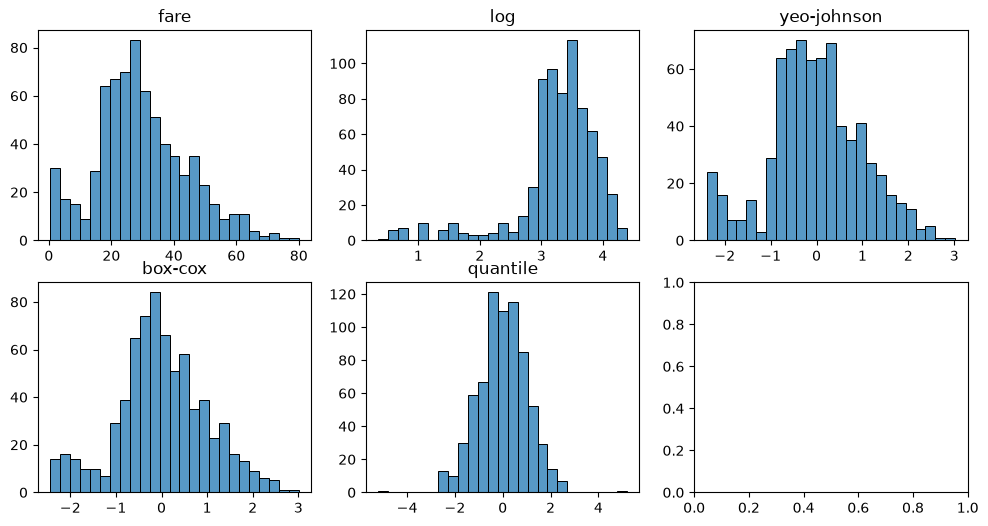

In [79]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

ft = FunctionTransformer(np.log1p)
yj = PowerTransformer(method='yeo-johnson')
bc = PowerTransformer(method='box-cox')
qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)

age_ft = ft.transform(df.Age)
age_yj = yj.fit_transform(df[['Age']])
age_bc = bc.fit_transform(df[['Age']])
age_qt = qt.fit_transform(df[['Age']])

sns.histplot(df.Age.values, ax=axes[0, 0], bins=25).set_title('fare')
sns.histplot(age_ft.values, ax=axes[0, 1], bins=25).set_title('log')
sns.histplot(age_yj[:, 0], ax=axes[0, 2], bins=25).set_title('yeo-johnson')
sns.histplot(age_bc[:, 0], ax=axes[1, 0], bins=25).set_title('box-cox')
sns.histplot(age_qt[:, 0], ax=axes[1, 1], bins=25).set_title('quantile')

for row in axes:
    for ax in row:
        ax.set_ylabel('')
plt.show()

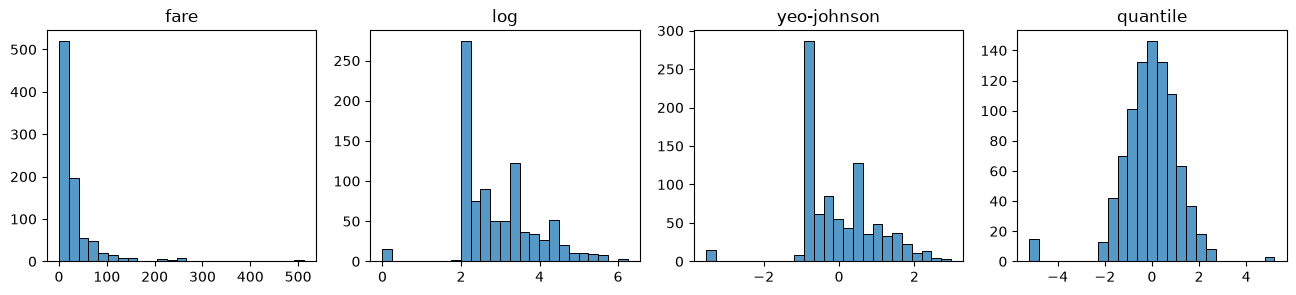

In [80]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))

ft = FunctionTransformer(np.log1p)
yj = PowerTransformer(method='yeo-johnson')
qt = QuantileTransformer(n_quantiles=100, output_distribution='normal', random_state=42)

fare_ft = ft.transform(df.Fare)
fare_yj = yj.fit_transform(df[['Fare']])
fare_qt = qt.fit_transform(df[['Fare']])

sns.histplot(df.Fare.values, ax=axes[0], bins=25).set_title('fare')
sns.histplot(fare_ft.values, ax=axes[1], bins=25).set_title('log')
sns.histplot(fare_yj[:, 0], ax=axes[2], bins=25).set_title('yeo-johnson')
sns.histplot(fare_qt[:, 0], ax=axes[3], bins=25).set_title('quantile')

for ax in axes:
    ax.set_ylabel('')
plt.show()